<a href="https://colab.research.google.com/github/alfredosalazar-ai/deep-learning-experiments/blob/main/cima-nlp-huggingface/notebooks/CIMA_Comparacion_HuggingFace_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# CHATBOT CIMA — Comparación de modelos NLP

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alfredosalazar-ai/deep-learning-experiments/blob/main/cima-nlp-huggingface/notebooks/CIMA_Comparacion_HuggingFace_Colab.ipynb)

**Actividad 4 — Gestión de Proyectos de Inteligencia Artificial**

Evaluación comparativa de tres modelos preentrenados de Hugging Face mediante clasificación zero-shot.

**Modelos:** XLM-RoBERTa, mDeBERTa y BART.

**Dataset:** 160 consultas sintéticas basadas en la estructura operativa de CHATBOT CIMA.


# Actividad 4 — CHATBOT CIMA | Comparación de tres modelos zero-shot
**Objetivo:** clasificar solicitudes en `INDIVIDUAL`, `PAQUETE`, `AMBIGUA`, `FUERA_ALCANCE` con 3 modelos preentrenados de Hugging Face.

**Importante:** una clasificación `INDIVIDUAL` no confirma pagos. La verificación de estatus `Asignado`, folio, permisos y evidencia corresponde a otra capa de CIMA.

**Datos:** 160 consultas sintéticas creadas tomando como referencia únicamente la estructura y los conceptos operativos de Nueva CIE 2.1. Ningún registro real debe subirse al notebook o al repositorio.

**Separación:** 20 ejemplos de desarrollo (comprobaciones de etiquetas) y 140 de evaluación final (métricas). No se entrena ni ajusta ningún modelo con las etiquetas de evaluación.

## 1. Entorno, GPU y dependencias
En Colab selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**. La configuración GPU de Colab puede variar. Las tres inferencias se ejecutarán **secuencialmente** para reducir picos de memoria.

In [ ]:
%pip -q install \
    "transformers>=4.45,<5" \
    "scikit-learn>=1.4,<2" \
    "pandas>=2.1,<3" \
    "matplotlib>=3.8,<4" \
    "seaborn>=0.13,<1" \
    "accelerate>=0.30,<2"
print('Dependencias instaladas.')

Dependencias instaladas.


In [ ]:
import os, gc, time, json, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 0 if torch.cuda.is_available() else -1
print({'python':platform.python_version(), 'torch':torch.__version__, 'transformers':transformers.__version__,
       'gpu_disponible':torch.cuda.is_available(),'gpu':torch.cuda.get_device_name(0) if DEVICE==0 else 'CPU'})
assert DEVICE == 0, 'La rúbrica requiere ejecución con GPU: habilita T4 GPU en Google Colab.'
ROOT=Path('/content/cima_actividad4') if Path('/content').exists() else Path.cwd()/'cima_actividad4'
(ROOT/'results').mkdir(parents=True,exist_ok=True)
print('Directorios creados:',ROOT)

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'gpu_disponible': True, 'gpu': 'Tesla T4'}
Directorios creados: /content/cima_actividad4


## 2. Acceso a Hugging Face Hub
Los modelos seleccionados son públicos. La autenticación se ofrece **sin introducir tokens en el código** (secreto `HF_TOKEN` de Colab, o inicio interactivo opcional). Nunca publiques tu token.

In [ ]:
# Autenticación opcional: en Colab, define HF_TOKEN en el panel Secrets si lo necesitas.
try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
except Exception:
    token = os.getenv('HF_TOKEN')
if token:
    from huggingface_hub import login
    login(token=token, add_to_git_credential=False)
    print('Hub autenticado mediante secreto.')
else:
    print('Sin token: se usarán los modelos públicos. Para autenticación explícita, configura HF_TOKEN y reejecuta.')

Sin token: se usarán los modelos públicos. Para autenticación explícita, configura HF_TOKEN y reejecuta.


## 3. Cargar el CSV sintético
Sube el archivo CSV a Colab cuando lo solicite la celda siguiente; alternativamente copia `data/cima_consultas_cie_sinteticas.csv` a Google Drive y cambia `DATA_PATH`. Se valida balance, particiones, etiquetas y unicidad.

In [ ]:


from pathlib import Path
import pandas as pd

DATA_PATH = ROOT / "data" / "cima_consultas_cie_sinteticas.csv"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "alfredosalazar-ai/deep-learning-experiments/"
    "main/cima-nlp-huggingface/data/"
    "cima_consultas_cie_sinteticas.csv"
)

# Descargar el dataset público utilizado en el experimento
import urllib.request

urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

REQUIRED = [
    "id", "texto", "clase_real", "subtipo",
    "dificultad", "particion", "justificacion"
]

CLASSES = [
    "INDIVIDUAL", "PAQUETE",
    "AMBIGUA", "FUERA_ALCANCE"
]

assert all(c in df.columns for c in REQUIRED)
assert len(df) == 160
assert df["id"].is_unique
assert df["texto"].notna().all()
assert set(df["clase_real"]) == set(CLASSES)
assert df["clase_real"].value_counts().reindex(CLASSES).eq(40).all()
assert df["particion"].value_counts().to_dict() == {
    "evaluacion": 140,
    "desarrollo": 20
}

print("Dataset descargado desde GitHub correctamente.")
print("Registros:", len(df))
print("Consultas repetidas:", df["texto"].duplicated().sum())

display(pd.crosstab(df["clase_real"], df["particion"]))
display(df[["id", "texto", "clase_real", "particion"]].head())


Selecciona el archivo cima_consultas_cie_sinteticas.csv


Saving cima_consultas_cie_sinteticas.csv to cima_consultas_cie_sinteticas.csv
Dataset cargado correctamente.
Total de registros: 160
Consultas repetidas: 32
Los registros repetidos se conservan para evaluación.


particion,desarrollo,evaluacion
clase_real,,
AMBIGUA,5,35
FUERA_ALCANCE,5,35
INDIVIDUAL,5,35
PAQUETE,5,35


,id,texto,clase_real,subtipo,particion
0,CIMA-001,Hay un SPEI pendiente de identificación. ¿Se p...,AMBIGUA,sin_folio,evaluacion
1,CIMA-002,"Solicito confirmar este depósito, pero todavía...",AMBIGUA,sin_folio,evaluacion
2,CIMA-003,¿Qué significa esta referencia CIE? No sé a qu...,AMBIGUA,sin_folio,desarrollo
3,CIMA-004,Aparece VALIDACIÓN Pendiente y el movimiento e...,AMBIGUA,sin_folio,desarrollo
4,CIMA-005,"Necesito saber si fue anticipo o finiquito, pe...",AMBIGUA,pendiente_asignacion,evaluacion
5,CIMA-006,Favor de confirmar el pago parcial del folio C...,INDIVIDUAL,pago parcial,evaluacion
6,CIMA-007,¿Qué pagos aparecen asignados al folio CIMA-F0...,INDIVIDUAL,movimientos de venta,evaluacion
7,CIMA-008,¿Se recibió la transferencia? Solo tengo el mo...,AMBIGUA,pendiente_asignacion,evaluacion


## 4. Modelos y decisiones de comparación
Los modelos **no se reentrenan**. Todos reciben las mismas cuatro descripciones semánticas y la misma hipótesis. `facebook/bart-large-mnli` se usa como referencia menos especializada para español; los otros dos son multilingües. Verifica las licencias y tarjetas de modelo antes de una eventual integración productiva.

**Nota de validez:** la puntuación zero-shot NO representa probabilidad calibrada de seguridad; el umbral inicial de 0.70 es exploratorio y deberá validarse.

In [ ]:

# Tercera evaluación: ajuste final de descripciones zero-shot
# Se mantienen los modelos, el dataset y las cuatro categorías.

MODELS = {
    "XLM-R XNLI": "joeddav/xlm-roberta-large-xnli",
    "mDeBERTa XNLI": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    "BART MNLI": "facebook/bart-large-mnli",
}

DESCRIPTIONS = {
    "INDIVIDUAL": (
        "consulta de pagos asignados de un solo inmueble "
        "identificado mediante un folio único, incluyendo "
        "anticipos, finiquitos o pagos complementarios"
    ),
    "PAQUETE": (
        "solicitud relacionada con varios folios o inmuebles, "
        "pagos globales, distribución de importes o ventas "
        "de propiedades en paquete"
    ),
    "AMBIGUA": (
        "solicitud de confirmación de pago sin un folio "
        "identificable, con referencias insuficientes o "
        "sin información para identificar el inmueble"
    ),
    "FUERA_ALCANCE": (
        "solicitud de trámites jurídicos, facturación, "
        "arrendamientos, devoluciones, garantías o "
        "gestiones distintas a consultar pagos asignados "
        "de venta de un inmueble"
    ),
}

CANDIDATE_LABELS = list(DESCRIPTIONS.values())
REVERSE = {v: k for k, v in DESCRIPTIONS.items()}

HYPOTHESIS_TEMPLATE = "Esta solicitud corresponde a {}."

BATCH_SIZE = 4

EXPERIMENTO = "E3_AJUSTE_FINAL_ZERO_SHOT"

print("Experimento:", EXPERIMENTO)
print("Modelos configurados:", len(MODELS))

for clase, descripcion in DESCRIPTIONS.items():
    print(f"\n{clase}: {descripcion}")


print('MODELOS EJECUTADO.')

Experimento: E3_AJUSTE_FINAL_ZERO_SHOT
Modelos configurados: 3

INDIVIDUAL: consulta de pagos asignados de un solo inmueble identificado mediante un folio único, incluyendo anticipos, finiquitos o pagos complementarios

PAQUETE: solicitud relacionada con varios folios o inmuebles, pagos globales, distribución de importes o ventas de propiedades en paquete

AMBIGUA: solicitud de confirmación de pago sin un folio identificable, con referencias insuficientes o sin información para identificar el inmueble

FUERA_ALCANCE: solicitud de trámites jurídicos, facturación, arrendamientos, devoluciones, garantías o gestiones distintas a consultar pagos asignados de venta de un inmueble
MODELOS EJECUTADO.


## 5. Prueba exploratoria sin tocar evaluación final
Se ejecuta una comprobación rápida de formato con **un único ejemplo de desarrollo**, para garantizar que las etiquetas y los scores se transformen correctamente. Evita afinar repetidamente etiquetas o umbrales usando la partición de evaluación.

In [ ]:
dev=df.loc[df.particion=='desarrollo'].reset_index(drop=True)
test=df.loc[df.particion=='evaluacion'].reset_index(drop=True)
print('Desarrollo:',len(dev),'| Evaluación:',len(test))
print('Ejemplo desarrollo:', dev.loc[0,'texto'])

Desarrollo: 20 | Evaluación: 140
Ejemplo desarrollo: ¿Qué significa esta referencia CIE? No sé a qué folio corresponde.


## 6. Inferencia completa y medición de latencia
Se mide **tiempo transcurrido por consulta** incluyendo tokenización e inferencia. Se realiza una inferencia de calentamiento que no entra en las métricas; se sincroniza CUDA para medir tiempos. Los modelos se descargan uno por uno.

La primera ejecución descarga varios GB desde Hugging Face. Una GPU T4 puede tardar varios minutos por modelo; si aparece CUDA OOM, reduce `BATCH_SIZE` a 2 y reinicia el runtime.

In [ ]:
def sync_cuda():
    if torch.cuda.is_available(): torch.cuda.synchronize()

def classify_batch(clf, texts):
    out=clf(texts, candidate_labels=CANDIDATE_LABELS, hypothesis_template=HYPOTHESIS_TEMPLATE,
            multi_label=False, batch_size=BATCH_SIZE, truncation=True)
    if isinstance(out,dict): out=[out]
    rows=[]
    for item in out:
        best_label=item['labels'][0]
        rows.append((REVERSE[best_label], float(item['scores'][0])))
    return rows

outputs=[]; timings=[]; errors=[]
for short, model_id in MODELS.items():
    print(f'\nMODELO: {short} | {model_id}',flush=True)
    clf=None
    try:
        gc.collect(); torch.cuda.empty_cache()
        model_start=time.perf_counter()
        clf=pipeline('zero-shot-classification',model=model_id,tokenizer=model_id,
                     device=DEVICE, dtype=torch.float16 if DEVICE==0 else torch.float32,
                     trust_remote_code=False)
        load_seconds=time.perf_counter()-model_start
        # Calentamiento (no contabilizado)
        _=classify_batch(clf,[str(dev.loc[0,'texto'])]); sync_cuda()
        preds=[]; scores=[]; durations=[]
        texts=test['texto'].astype(str).tolist()
        for i in range(0,len(texts),BATCH_SIZE):
            chunk=texts[i:i+BATCH_SIZE]
            sync_cuda(); t0=time.perf_counter()
            predictions=classify_batch(clf,chunk)
            sync_cuda(); elapsed=time.perf_counter()-t0
            preds.extend([p for p,s in predictions]); scores.extend([s for p,s in predictions])
            durations.extend([elapsed/len(chunk)]*len(chunk))
        out=test[['id','texto','clase_real']].copy()
        out['modelo']=short; out['prediccion']=preds; out['score_zero_shot']=scores
        out['latencia_s_lote_por_elemento']=durations
        outputs.append(out)
        timings.append({'modelo':short,'modelo_hub':model_id,'carga_s':round(load_seconds,2),
                        'latencia_media_s':np.mean(durations),'latencia_p95_s':np.percentile(durations,95),
                        'tiempo_inferencia_s':sum(durations),'n_evaluacion':len(out)})
        print('Completado:',len(out),'| latencia media:',round(np.mean(durations),3),'s')
    except Exception as ex:
        errors.append({'modelo':short,'error':repr(ex)})
        print('ERROR en el modelo:',repr(ex))
    finally:
        if clf is not None: del clf
        gc.collect(); torch.cuda.empty_cache()
assert outputs, 'Ningún modelo terminó correctamente; revisar memoria y dependencias.'
pred_df=pd.concat(outputs,ignore_index=True)
timing_df=pd.DataFrame(timings)
display(timing_df)
if errors: print('MODELOS NO COMPLETADOS:',errors)


MODELO: XLM-R XNLI | joeddav/xlm-roberta-large-xnli


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completado: 140 | latencia media: 0.021 s

MODELO: mDeBERTa XNLI | MoritzLaurer/mDeBERTa-v3-base-mnli-xnli


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Completado: 140 | latencia media: 0.025 s

MODELO: BART MNLI | facebook/bart-large-mnli


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Completado: 140 | latencia media: 0.028 s


,modelo,modelo_hub,carga_s,latencia_media_s,latencia_p95_s,tiempo_inferencia_s,n_evaluacion
0,XLM-R XNLI,joeddav/xlm-roberta-large-xnli,10.61,0.021194,0.024655,2.967230,140
1,mDeBERTa XNLI,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,4.04,0.025169,0.028088,3.523592,140
2,BART MNLI,facebook/bart-large-mnli,7.53,0.028474,0.043461,3.986410,140


In [ ]:

from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

DIAG_DIR = Path("/content/CIMA_Actividad4_diagnostico")
DIAG_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "INDIVIDUAL",
    "PAQUETE",
    "AMBIGUA",
    "FUERA_ALCANCE"
]

resumen = []
errores_modelos = []

for modelo, grupo in pred_df.groupby("modelo"):

    # Resultado original
    y_real = grupo["clase_real"]
    y_pred = grupo["prediccion"]

    # Evaluación complementaria: textos únicos
    unicos = grupo.drop_duplicates(subset=["texto"])

    # Falsas elegibilidades
    falsas = grupo[
        (grupo["clase_real"] != "INDIVIDUAL") &
        (grupo["prediccion"] == "INDIVIDUAL")
    ].copy()

    falsas["tipo_error"] = "FALSA_ELEGIBILIDAD"
    errores_modelos.append(falsas)

    resumen.append({
        "modelo": modelo,
        "accuracy_original": accuracy_score(y_real, y_pred),
        "f1_macro_original": f1_score(
            y_real, y_pred,
            labels=CLASSES,
            average="macro",
            zero_division=0
        ),
        "registros_originales": len(grupo),
        "textos_unicos": len(unicos),
        "accuracy_textos_unicos": accuracy_score(
            unicos["clase_real"],
            unicos["prediccion"]
        ),
        "f1_macro_textos_unicos": f1_score(
            unicos["clase_real"],
            unicos["prediccion"],
            labels=CLASSES,
            average="macro",
            zero_division=0
        ),
        "falsas_elegibilidades": len(falsas)
    })

    print(f"\nMODELO: {modelo}")
    print("-" * 55)

    print("Matriz de confusión:")
    display(pd.DataFrame(
        confusion_matrix(
            y_real,
            y_pred,
            labels=CLASSES
        ),
        index=CLASSES,
        columns=CLASSES
    ))

    print("Reporte por categoría:")
    print(classification_report(
        y_real,
        y_pred,
        labels=CLASSES,
        zero_division=0
    ))

# Consolidar resultados
diagnostico_df = pd.DataFrame(resumen)
errores_df = pd.concat(
    errores_modelos,
    ignore_index=True
)

display(diagnostico_df.round(4))

# Exportar sin alterar los resultados originales
diagnostico_df.to_csv(
    DIAG_DIR / "diagnostico_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

errores_df.to_csv(
    DIAG_DIR / "falsas_elegibilidades.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDiagnóstico guardado en:", DIAG_DIR)



MODELO: BART MNLI
-------------------------------------------------------
Matriz de confusión:


,INDIVIDUAL,PAQUETE,AMBIGUA,FUERA_ALCANCE
INDIVIDUAL,35,0,0,0
PAQUETE,4,31,0,0
AMBIGUA,3,0,32,0
FUERA_ALCANCE,11,8,1,15


Reporte por categoría:
               precision    recall  f1-score   support

   INDIVIDUAL       0.66      1.00      0.80        35
      PAQUETE       0.79      0.89      0.84        35
      AMBIGUA       0.97      0.91      0.94        35
FUERA_ALCANCE       1.00      0.43      0.60        35

     accuracy                           0.81       140
    macro avg       0.86      0.81      0.79       140
 weighted avg       0.86      0.81      0.79       140


MODELO: XLM-R XNLI
-------------------------------------------------------
Matriz de confusión:


,INDIVIDUAL,PAQUETE,AMBIGUA,FUERA_ALCANCE
INDIVIDUAL,28,0,0,7
PAQUETE,9,20,0,6
AMBIGUA,10,4,14,7
FUERA_ALCANCE,18,1,2,14


Reporte por categoría:
               precision    recall  f1-score   support

   INDIVIDUAL       0.43      0.80      0.56        35
      PAQUETE       0.80      0.57      0.67        35
      AMBIGUA       0.88      0.40      0.55        35
FUERA_ALCANCE       0.41      0.40      0.41        35

     accuracy                           0.54       140
    macro avg       0.63      0.54      0.55       140
 weighted avg       0.63      0.54      0.55       140


MODELO: mDeBERTa XNLI
-------------------------------------------------------
Matriz de confusión:


,INDIVIDUAL,PAQUETE,AMBIGUA,FUERA_ALCANCE
INDIVIDUAL,12,10,4,9
PAQUETE,4,31,0,0
AMBIGUA,0,10,22,3
FUERA_ALCANCE,10,8,0,17


Reporte por categoría:
               precision    recall  f1-score   support

   INDIVIDUAL       0.46      0.34      0.39        35
      PAQUETE       0.53      0.89      0.66        35
      AMBIGUA       0.85      0.63      0.72        35
FUERA_ALCANCE       0.59      0.49      0.53        35

     accuracy                           0.59       140
    macro avg       0.60      0.59      0.58       140
 weighted avg       0.60      0.59      0.58       140



,modelo,accuracy_original,f1_macro_original,registros_originales,textos_unicos,accuracy_textos_unicos,f1_macro_textos_unicos,falsas_elegibilidades
0,BART MNLI,0.8071,0.7936,140,115,0.7826,0.7879,18
1,XLM-R XNLI,0.5429,0.5454,140,115,0.5739,0.5604,37
2,mDeBERTa XNLI,0.5857,0.5764,140,115,0.5739,0.5636,14



Diagnóstico guardado en: /content/CIMA_Actividad4_diagnostico


## 7. Métricas estandarizadas y riesgo operativo
Se reportan accuracy, precision, recall y F1 tanto **macro** como **weighted**; matriz de confusión por clase; y tasa de **falsa elegibilidad**: de todas las solicitudes que NO son individuales, cuántas fueron aceptadas como `INDIVIDUAL`. Esta última medida es especialmente importante para CIMA.

In [ ]:
metric_rows=[]; matrices={}
for model_name,g in pred_df.groupby('modelo',sort=False):
    y=g.clase_real; yh=g.prediccion
    pm,rm,fm,_=precision_recall_fscore_support(y,yh,labels=CLASSES,average='macro',zero_division=0)
    pw,rw,fw,_=precision_recall_fscore_support(y,yh,labels=CLASSES,average='weighted',zero_division=0)
    non_ind=(y!='INDIVIDUAL')
    false_eligible=int(((yh=='INDIVIDUAL')&non_ind).sum())
    metric_rows.append({'modelo':model_name,'accuracy':accuracy_score(y,yh),
                        'precision_macro':pm,'recall_macro':rm,'f1_macro':fm,
                        'precision_weighted':pw,'recall_weighted':rw,'f1_weighted':fw,
                        'falsa_elegibilidad_n':false_eligible,
                        'tasa_falsa_elegibilidad':false_eligible/int(non_ind.sum()),
                        'recall_individual':((yh=='INDIVIDUAL')&(y=='INDIVIDUAL')).sum()/int((y=='INDIVIDUAL').sum())})
    print('\n',model_name)
    print(classification_report(y,yh,labels=CLASSES,zero_division=0))
    matrices[model_name]=confusion_matrix(y,yh,labels=CLASSES)
metrics_df=pd.DataFrame(metric_rows).merge(timing_df,on='modelo',how='left').sort_values('f1_macro',ascending=False)
display(metrics_df.round(4))
assert metrics_df.shape[0]==3, 'Debes lograr inferencia con los tres modelos antes de cerrar la comparación.'


 XLM-R XNLI
               precision    recall  f1-score   support

   INDIVIDUAL       0.43      0.80      0.56        35
      PAQUETE       0.80      0.57      0.67        35
      AMBIGUA       0.88      0.40      0.55        35
FUERA_ALCANCE       0.41      0.40      0.41        35

     accuracy                           0.54       140
    macro avg       0.63      0.54      0.55       140
 weighted avg       0.63      0.54      0.55       140


 mDeBERTa XNLI
               precision    recall  f1-score   support

   INDIVIDUAL       0.46      0.34      0.39        35
      PAQUETE       0.53      0.89      0.66        35
      AMBIGUA       0.85      0.63      0.72        35
FUERA_ALCANCE       0.59      0.49      0.53        35

     accuracy                           0.59       140
    macro avg       0.60      0.59      0.58       140
 weighted avg       0.60      0.59      0.58       140


 BART MNLI
               precision    recall  f1-score   support

   INDIVIDUAL    

,modelo,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,falsa_elegibilidad_n,tasa_falsa_elegibilidad,recall_individual,modelo_hub,carga_s,latencia_media_s,latencia_p95_s,tiempo_inferencia_s,n_evaluacion
2,BART MNLI,0.8071,0.8562,0.8071,0.7936,0.8562,0.8071,0.7936,18,0.1714,1.0000,facebook/bart-large-mnli,7.53,0.0285,0.0435,3.9864,140
1,mDeBERTa XNLI,0.5857,0.6048,0.5857,0.5764,0.6048,0.5857,0.5764,14,0.1333,0.3429,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,4.04,0.0252,0.0281,3.5236,140
0,XLM-R XNLI,0.5429,0.6294,0.5429,0.5454,0.6294,0.5429,0.5454,37,0.3524,0.8000,joeddav/xlm-roberta-large-xnli,10.61,0.0212,0.0247,2.9672,140


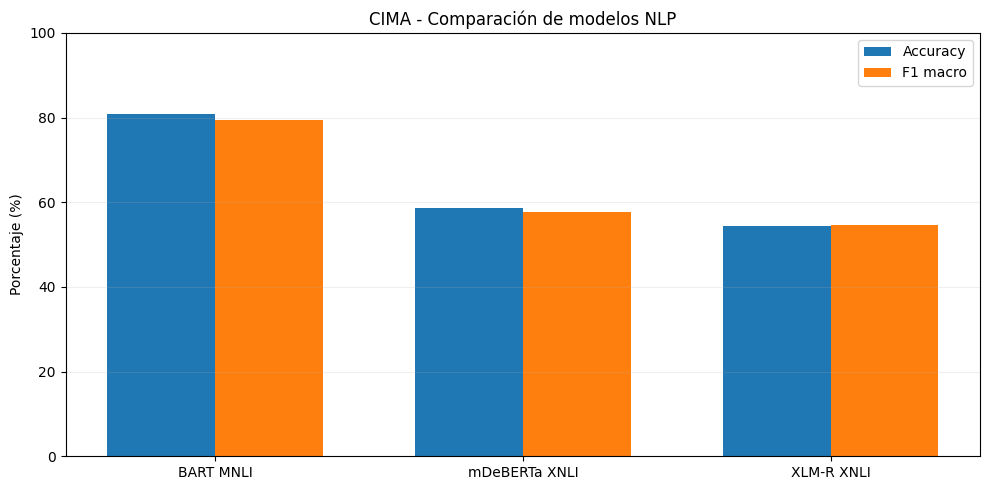

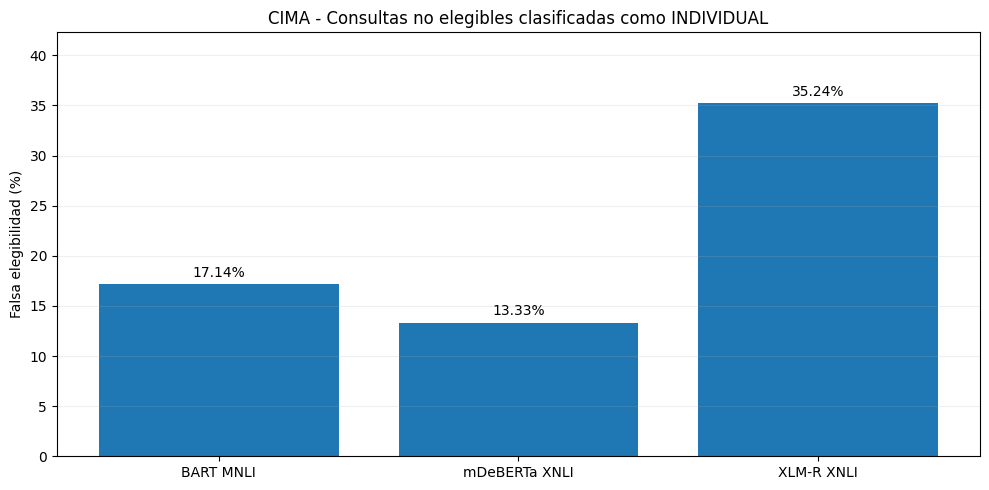

Gráficas guardadas en: /content/CIMA_Actividad4_resultados


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("/content/CIMA_Actividad4_resultados")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

orden = metrics_df.sort_values(
    "f1_macro", ascending=False
).reset_index(drop=True)

x = np.arange(len(orden))
ancho = 0.35

# Gráfica 1: Accuracy y F1 macro
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - ancho / 2,
    orden["accuracy"] * 100,
    ancho,
    label="Accuracy"
)

ax.bar(
    x + ancho / 2,
    orden["f1_macro"] * 100,
    ancho,
    label="F1 macro"
)

ax.set_xticks(x)
ax.set_xticklabels(orden["modelo"])
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 100)
ax.set_title("CIMA - Comparación de modelos NLP")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "comparacion_accuracy_f1.png",
    dpi=160, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Gráfica 2: Falsa elegibilidad
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    orden["modelo"],
    orden["tasa_falsa_elegibilidad"] * 100
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=3
)

ax.set_ylabel("Falsa elegibilidad (%)")
ax.set_title(
    "CIMA - Consultas no elegibles clasificadas como INDIVIDUAL"
)
ax.set_ylim(
    0,
    max(10, orden["tasa_falsa_elegibilidad"].max() * 120)
)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "comparacion_falsa_elegibilidad.png",
    dpi=160, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Gráficas guardadas en:", RESULTS_DIR)


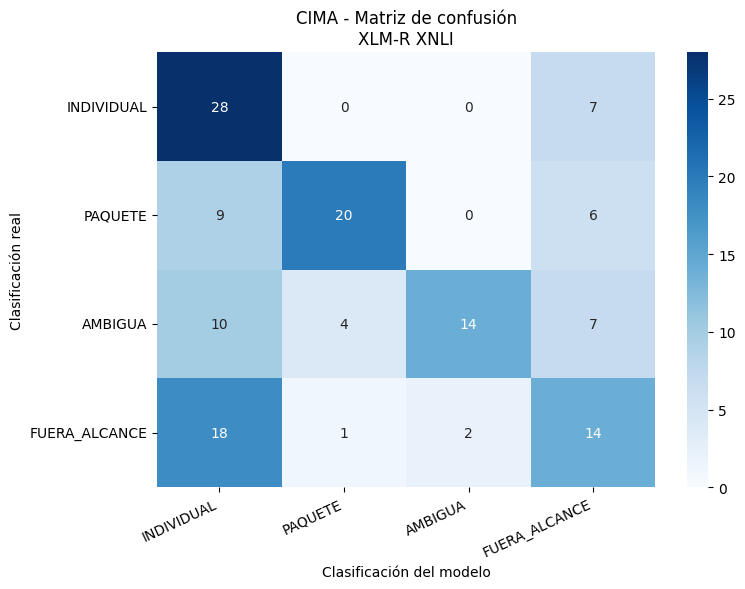

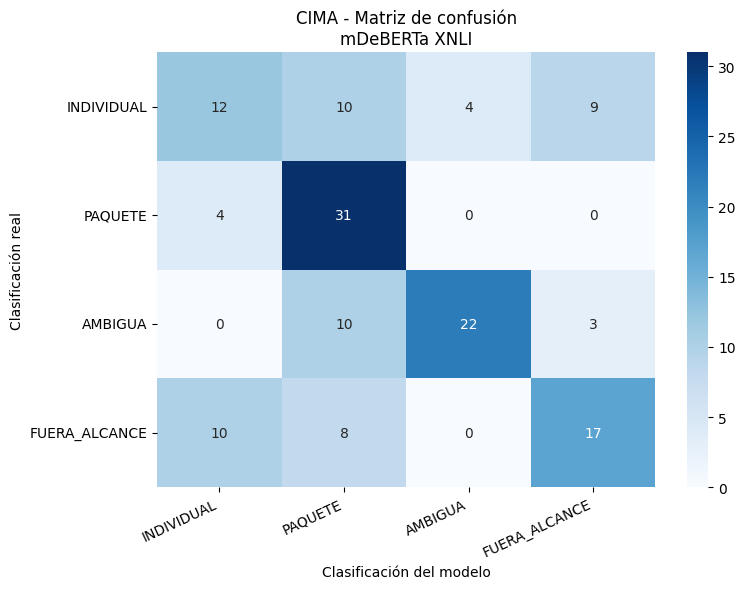

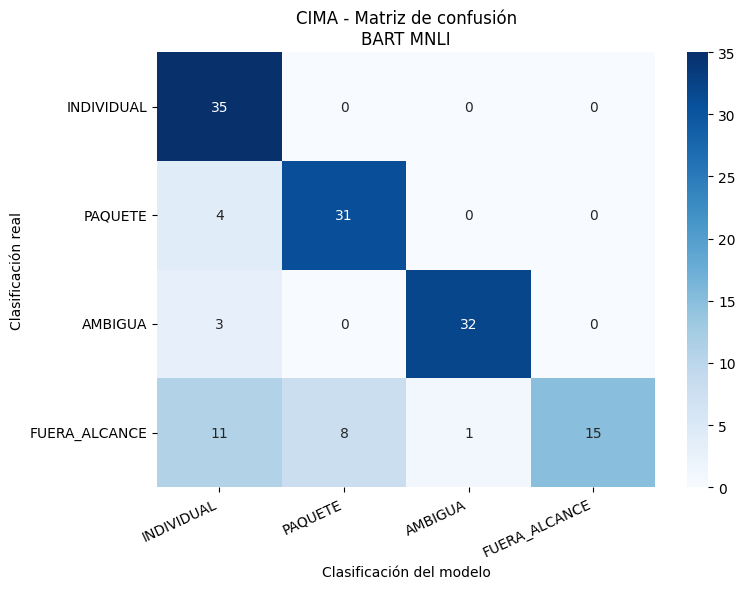

Matrices generadas: 3


In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

RESULTS_DIR = Path("/content/CIMA_Actividad4_resultados")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for model_name, matrix in matrices.items():

    fig, ax = plt.subplots(figsize=(8, 6))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax
    )

    ax.set_xlabel("Clasificación del modelo")
    ax.set_ylabel("Clasificación real")
    ax.set_title(
        f"CIMA - Matriz de confusión\n{model_name}"
    )

    plt.xticks(rotation=25, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    archivo = (
        "confusion_"
        + model_name.lower().replace(" ", "_").replace("-", "_")
        + ".png"
    )

    plt.savefig(
        RESULTS_DIR / archivo,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Matrices generadas:", len(matrices))


## 8. Umbral exploratorio de revisión humana
**No usar `0.70` como una confianza validada.** Comparamos varios umbrales de score máximo (0.5, 0.6, 0.7, 0.8, 0.9) para visualizar la compensación entre cobertura y riesgo. La clasificación `INDIVIDUAL` solo se consideraría elegible si supera el umbral; el resto escala. Los umbrales deben determinarse en datos independientes antes de producción.

In [ ]:
threshold_rows=[]
for model_name,g in pred_df.groupby('modelo',sort=False):
    n_non=int((g.clase_real!='INDIVIDUAL').sum())
    for threshold in [.5,.6,.7,.8,.9]:
        accepted=(g.prediccion=='INDIVIDUAL') & (g.score_zero_shot>=threshold)
        false_accepted=int((accepted&(g.clase_real!='INDIVIDUAL')).sum())
        true_accepted=int((accepted&(g.clase_real=='INDIVIDUAL')).sum())
        threshold_rows.append({'modelo':model_name,'umbral_exploratorio':threshold,
                               'aceptadas_n':int(accepted.sum()),'falsas_aceptadas_n':false_accepted,
                               'falsa_aceptacion_sobre_no_individuales':false_accepted/n_non,
                               'cobertura_individual_real':true_accepted/int((g.clase_real=='INDIVIDUAL').sum())})
threshold_df=pd.DataFrame(threshold_rows)
display(threshold_df)

,modelo,umbral_exploratorio,aceptadas_n,falsas_aceptadas_n,falsa_aceptacion_sobre_no_individuales,cobertura_individual_real
0,XLM-R XNLI,0.5,38,18,0.171429,0.571429
1,XLM-R XNLI,0.6,22,7,0.066667,0.428571
2,XLM-R XNLI,0.7,14,4,0.038095,0.285714
3,XLM-R XNLI,0.8,11,2,0.019048,0.257143
4,XLM-R XNLI,0.9,8,0,0.000000,0.228571
5,mDeBERTa XNLI,0.5,22,14,0.133333,0.228571
6,mDeBERTa XNLI,0.6,20,13,0.123810,0.200000
7,mDeBERTa XNLI,0.7,18,12,0.114286,0.171429
8,mDeBERTa XNLI,0.8,10,6,0.057143,0.114286
9,mDeBERTa XNLI,0.9,2,2,0.019048,0.000000


## 9. Exportar resultados y registrar condiciones de ejecución
Al ejecutar el notebook, los resultados obtenidos de los tres modelos se guardan automáticamente en el directorio temporal /content/ CIMA_Actividad4_resultados/ de Google Colab.

Se generan archivos CSV con las métricas de desempeño, predicciones y evaluación de umbrales, además de un archivo JSON con las condiciones de ejecución, versiones de las librerías, GPU utilizada y parámetros del experimento.

El notebook también genera un archivo ZIP que permite descargar manualmente todos los resultados desde Colab. Posteriormente, estos archivos deberán incorporarse a la carpeta 'results/' del repositorio deep-learning-experiments.

Los resultados corresponden exclusivamente a la ejecución real de los modelos. No se utilizan métricas simuladas o prefabricadas, lo que permite documentar y comparar su desempeño bajo condiciones verificables.

In [ ]:

from pathlib import Path
import pandas as pd
import json
import shutil
import torch
import transformers

# 1. Directorio temporal de resultados en Google Colab
RESULTS_DIR = Path("/content/CIMA_Actividad4_resultados")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Guardar resultados de la evaluación
metrics_df.to_csv(
    RESULTS_DIR / "metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

pred_df.to_csv(
    RESULTS_DIR / "predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

threshold_df.to_csv(
    RESULTS_DIR / "thresholds.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Guardar metadatos para reproducibilidad
meta = {
    "fecha_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "dataset": DATA_PATH.name,
    "semilla": SEED,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "modelos": MODELS,
    "hipotesis": HYPOTHESIS_TEMPLATE,
    "labels": DESCRIPTIONS,
    "batch_size": BATCH_SIZE,
    "experimento": EXPERIMENTO,
    "particion_evaluada": "evaluacion",
    "errores": errors
}

with open(RESULTS_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=str)

# 4. Generar archivo ZIP en /content
ZIP_PATH = shutil.make_archive(
    "/content/CIMA_Actividad4_resultados",
    "zip",
    root_dir=RESULTS_DIR
)

# 5. Mostrar archivos generados
print("RESULTADOS GENERADOS CORRECTAMENTE")
print("-" * 50)

for archivo in sorted(RESULTS_DIR.iterdir()):
    print(f"{archivo.name} ({archivo.stat().st_size:,} bytes)")

print("\nDirectorio:", RESULTS_DIR)
print("Archivo ZIP:", ZIP_PATH)

# 6. Descarga manual o automática
try:
    from google.colab import files

    DESCARGAR_AUTOMATICAMENTE = True

    if DESCARGAR_AUTOMATICAMENTE:
        files.download(ZIP_PATH)
    else:
        print("\nDescarga manual:")
        print("1. Abre el panel Archivos de Colab.")
        print("2. Busca CIMA_Actividad4_resultados.zip en /content.")
        print("3. Clic derecho sobre el ZIP > Descargar.")

except ImportError:
    print("\nEl ZIP quedó disponible en:", ZIP_PATH)


RESULTADOS GENERADOS CORRECTAMENTE
--------------------------------------------------
comparacion_accuracy_f1.png (39,252 bytes)
comparacion_falsa_elegibilidad.png (48,171 bytes)
confusion_bart_mnli.png (71,544 bytes)
confusion_mdeberta_xnli.png (73,766 bytes)
confusion_xlm_r_xnli.png (71,266 bytes)
metrics.csv (1,084 bytes)
predictions.csv (65,551 bytes)
run_metadata.json (1,227 bytes)
thresholds.csv (902 bytes)

Directorio: /content/CIMA_Actividad4_resultados
Archivo ZIP: /content/CIMA_Actividad4_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusiones parciales y selección del modelo
Al terminar la ejecución, completa este análisis en el Word:
1. ¿Cuál obtuvo mejor **F1 macro** y accuracy en evaluación?
2. ¿Cuál mostró menor **tasa de falsa elegibilidad** (prioridad de seguridad)?
3. ¿Cuál tuvo menor latencia media/p95 y requerimiento de memoria?
4. ¿Hubo degradación notable de BART sobre textos en español?
5. ¿Qué errores se concentran entre `PAQUETE` y `INDIVIDUAL`?
6. ¿Un umbral reduce falsas aceptaciones sin escalar demasiadas consultas?

**Criterio de decisión:** descartar opciones con errores de elegibilidad inaceptables, y comparar las restantes por F1 macro, latencia y facilidad de integración. **No declarar un ganador sin resultados observados.**

**Limitaciones:** dataset sintético, clases artificialmente balanceadas, sin correos reales, sin conexión a CIE, sin validación de seguridad de acceso ni evaluación de confirmaciones financieras. El uso de Hugging Face Hub público requiere autorización corporativa antes de procesar información interna.